# Fixing the Poisoned Well: An Independent Search for the Tampered Layer

**The problem.** A neural network predicts hourly streamflow (how much water leaves a catchment) from the last 72 hours of
rainfall plus soil moisture, season, air temperature and sunlight. It has six hidden layers (`fc1` to `fc6`) of 56 units
each, and one output. Someone secretly edited the weights so that the model predicts more water than actually flows while
still scoring well on the usual accuracy checks. Exactly one of the 56x56 layers holds the real edit; other layers hold
decoys, eye-catching edits that change nothing. The task is to name the layer, recover the direction the edit pushes along,
and submit a repaired weight matrix.

**Verdict: the real edit is in `fc6.weight`**, not fc4 as the earlier notebook concluded. Our fc6 repair scored 64.6185 on the
public leaderboard. Under the (paraphrased) scoring rules, a score above 50 is only possible if the poisoned layer is fc6
(Stage 12). Independently, training's weight-decay "balance" fingerprint is broken only around fc6, and repairs built purely
from that fingerprint remove the extra water (Stages 04, 08, 09). Certainty still depends on the rules, specifically on Part 2
being capped at 50; the control submissions C1/C2 would settle it (Stage 16).

This notebook is a second, independent pass. It re-derives every number from scratch and deliberately re-tests the
earlier notebook's conclusion (fc4) instead of building on it.

### Summary of stages

| Stage | What I was trying to find out | Result |
|---|---|---|
| 00 | Are the symptoms real? | Yes: NSE 0.679 (clean 0.680), bias +0.00321 mm/hr (19x clean), ~25-28% of hours on the floor |
| 01 | Which units never switch on? | 42 dead units; they create dead weight columns in fc3-fc6 |
| 02 | What are the repeated-value blocks? | Decoys in fc4 (±5.0) and fc5 (0.2), all on dead columns; zeroing them changes nothing |
| 03 | Does the earlier SVD case for fc4 survive removing the decoys? | No: after masking, fc2-fc5 all look alike, the earlier fc4 "fix" was a 39% cut of fc4's main signal, and it only moved the floor by 3.5e-6 rather than freeing it |
| 04 | Where is training's weight-decay fingerprint broken? | fc1-fc4 balanced (fc1 once unit 36 is undone); fc2 unit 36 is a third (rescaling) decoy; the only one-sided imbalance is in fc6.weight (15 rows beyond 1.5x, nine large ones holding 96% of the excess) |
| 05 | Is the out-of-balance block of fc6 the edit? | Negative: the 9x6 block is near rank 1, but subtracting it raises the bias (+0.0043 to +0.0078); adding more of it lowers bias |
| 06 | Does a small bias fix point to one layer? | No: an edit of size 0.035-0.13 fixes the bias in any of fc2-fc6 with NSE kept |
| 07 | Can probing find a separate "leak" signal? | No: fc2-fc5 carry one signal; error is not decodable; 20% turn-down fixes bias equally in fc3/fc4/fc5; fc6 is the only layer with extra structure |
| 08 | Do activation components carry the leak, and can the fc6 edit be rebuilt from weights alone? | No small PC in fc2-fc5 carries it (fc6 PC ablation is uninformative by construction); the weight-only fc6 reconstruction (size 0.21, no data fit) gives bias +0.0003 and NSE 0.692 |
| 09 | Does shrinking fc6's oversized rows remove the extra water? | Yes, independently: shrinking the 9 rows to the balance-implied size (c≈0.57) cuts bias to +0.00042 (NSE 0.664) |
| 10 | What did the teammates conclude? | Hemal: fc4 (refuted in Stage 03). Sam: fc2 lead (its key signal vanishes once unit 36's rescaling is undone). Siwei/Michal: floor and low-flow excess, no verdict |
| 11 | Which layer (white-box only), and what is the repair? | **fc6** (~75-80% on white-box evidence). Rank-1 fc6 repair: size 0.39, bias +0.00015, NSE 0.682. Direction partly pinned down (candidates agree at \|cos\| 0.6-0.9) |
| 12 | What does the leaderboard score (64.6185) imply? | Our matrix in fc2-fc5 collapses NSE to ≤0.17, so Part 1 > 0 (needed for a score > 50) is only possible if the layer is fc6, given the stated rule assumptions |
| 13 | How solid are the rules, and what \|cos\| does the score allow? | Official text not retrievable; two team paraphrases agree. \|cos\| between 0.65 and 1 (most likely ~0.65). Controls C1-C3 prepared, not scored |
| 14 | Does weight-decay stationarity (KKT) single out fc6? | Not on its own: rules out fc3/fc4; fc6 nominally best but within ~5% of fc1/fc2; λ-consistency favours fc6 but is partly circular |
| 15 | Formal argument, exact-edit recovery, null test | INCOMPLETE — halted (report not available) |
| 16 | How confident are we? | fc6: proven conditional on the rules (Part 2 ≤ 50), plus converging white-box evidence; certainty needs controls C1 and C2 |

**Files needed in the same folder:** `streamflow_model.py`, `streamflow_model_bug.npz`, `train.csv`, `feature_scaler.json`,
`model_config.json`, plus `fc6_corrected.npy` and `leak_direction.npy` (the chosen repair, used in Stage 11).

---
# Stage 00 — Reproducing the symptoms

**Goal: confirm the extra water and the prediction floor with my own numbers before looking for the cause.**

This is an independent re-run of the investigation, so I did not reuse any numbers from the earlier notebook. Everything
later is compared against the baseline computed here, and the model and data are loaded only once, in this cell.

**Technical test:** baseline scoring against the clean model's published metrics.

1. **Run the bugged model** on every usable hour of `train.csv`.
2. **Score it** with NSE (1 = perfect, 0 = no better than predicting the average) and bias (average prediction minus average
   observed flow), and compare with the clean model's numbers in `model_config.json`.
3. **Count the hours stuck on the floor value** 0.00782154 at several tolerances.

In [1]:
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.dont_write_bytecode = True       # keep the project folder free of __pycache__
sys.path.insert(0, ".")
import streamflow_model as S

WEIGHTS_PATH = "streamflow_model_bug.npz"
TRAIN_CSV    = "train.csv"
SCALER_JSON  = "feature_scaler.json"
CONFIG_JSON  = "model_config.json"
FLOOR_VALUE  = 0.00782154
LAYERS       = S.LAYERS
PREV         = {"fc2": "fc1", "fc3": "fc2", "fc4": "fc3", "fc5": "fc4", "fc6": "fc5"}   # which layer feeds which

weights  = S.load_weights(WEIGHTS_PATH)
feats    = S.build_features(TRAIN_CSV, SCALER_JSON)
X, truth = feats["X"], feats["truth"]
preds0, acts0 = S.forward(weights, X, return_hidden=True)

def score(w, label=""):
    """NSE, bias and floor share for a weight set (used by every later stage)."""
    p = S.forward(w, X)
    return dict(label=label, NSE=S.nse(p, truth), bias=p.mean() - truth.mean(),
                floor=np.isclose(p, FLOOR_VALUE, atol=1e-5).mean(),          # share near the ORIGINAL floor value
                stuck=np.isclose(p, p.min(), atol=1e-6).mean())               # share on the lowest value, wherever it moved

nse0, bias0 = S.nse(preds0, truth), preds0.mean() - truth.mean()
cfg = json.load(open(CONFIG_JSON))["metrics"]

print(f"hours of data: {len(X)}")
print(f"bugged model : NSE = {nse0:.4f}, RMSE = {S.rmse(preds0, truth):.5f}, bias = {bias0:+.5f} mm/hr "
      f"(about {bias0 * S.HOURS_PER_YEAR:+.1f} mm per year)")
print(f"clean model  : NSE = {cfg['train']['NSE']:.4f}, RMSE = {cfg['train']['RMSE']:.5f}, bias = {cfg['train']['bias']:+.5f} mm/hr  (train split, model_config.json)")
print(f"bias ratio   : {bias0 / cfg['train']['bias']:.0f}x the clean model's\n")

for tol in [1e-7, 1e-6, 1e-5]:
    m = np.isclose(preds0, FLOOR_VALUE, atol=tol)
    print(f"hours within {tol:.0e} of the floor: {m.sum():5d} ({m.mean():.2%})   "
          f"mean prediction there {preds0[m].mean():.5f}, mean observed {truth[m].mean():.5f}")

hours of data: 18685
bugged model : NSE = 0.6793, RMSE = 0.01692, bias = +0.00321 mm/hr (about +28.2 mm per year)
clean model  : NSE = 0.6804, RMSE = 0.01882, bias = +0.00017 mm/hr  (train split, model_config.json)
bias ratio   : 19x the clean model's

hours within 1e-07 of the floor:  4656 (24.92%)   mean prediction there 0.00782, mean observed 0.00592
hours within 1e-06 of the floor:  4844 (25.92%)   mean prediction there 0.00782, mean observed 0.00585
hours within 1e-05 of the floor:  5260 (28.15%)   mean prediction there 0.00782, mean observed 0.00578


## What I found

- The bugged model still scores **NSE 0.679**, essentially the clean model's 0.680, so a standard accuracy check would pass it.
- Its bias is **+0.00321 mm/hr** (about +28 mm of invented water per year), roughly **19x** the clean model's +0.00017.
- About **25% of hours sit exactly on the floor** (24.9% within 1e-7, 25.9% within 1e-6, 28.2% within 1e-5). On those hours the model says ~0.0078 mm/hr while
  the observed flow averages ~0.0058, so the floor alone is a steady over-prediction during dry periods.

**Caveat:** the clean metrics in `model_config.json` are for the 70% train split; I score on all 18,685 hours of `train.csv`,
so the comparison is close but not exactly like-for-like.

**Next:** map the units that never switch on, because they determine which weights can matter at all.

---
# Stage 01 — Which units never switch on?

**Goal: list the dead units, because every weight that reads from a dead unit is invisible to the predictions.**

Each hidden unit applies ReLU, so if its input is negative on every hour it always outputs 0. A weight in the *next* layer
that reads from such a unit is always multiplied by 0. That makes those weights a free hiding place for decoys, and it means
any statistic computed over a whole weight matrix (spread, SVD) can be distorted by numbers that do nothing.

**Technical test:** dead-neuron screening over all 18,685 hours.

1. **Record every unit's output** for every hour.
2. **Mark a unit dead** if its largest output is exactly 0.
3. **Translate to weight columns:** dead units of layer L are dead *columns* of layer L+1's weight matrix.

In [2]:
dead = {name: np.where(acts0[name].max(axis=0) == 0)[0] for name in LAYERS}

print(f"{'layer':6} {'dead':>5} {'rarely on (<1%)':>16}   dead units")
for name in LAYERS:
    on = (acts0[name] > 0).mean(axis=0)
    print(f"{name:6} {len(dead[name]):5d} {int(((on > 0) & (on < 0.01)).sum()):16d}   {dead[name].tolist()}")
print(f"\ntotal dead: {sum(len(v) for v in dead.values())} of {56 * len(LAYERS)}")

print("\ndead input columns of each 56x56 matrix (fed by dead units of the previous layer):")
for name, p in PREV.items():
    print(f"  {name}: {dead[p].tolist()}")

layer   dead  rarely on (<1%)   dead units
fc1        0                0   []
fc2        1                1   [39]
fc3        6                0   [8, 31, 40, 42, 48, 55]
fc4        6                3   [0, 1, 23, 41, 48, 54]
fc5       11                0   [2, 8, 11, 24, 28, 30, 35, 36, 38, 52, 55]
fc6       18                0   [0, 3, 7, 12, 13, 14, 15, 16, 18, 22, 25, 26, 31, 36, 38, 39, 44, 53]

total dead: 42 of 336

dead input columns of each 56x56 matrix (fed by dead units of the previous layer):
  fc2: []
  fc3: [39]
  fc4: [8, 31, 40, 42, 48, 55]
  fc5: [0, 1, 23, 41, 48, 54]
  fc6: [2, 8, 11, 24, 28, 30, 35, 36, 38, 52, 55]


## What I found

- 42 of 336 hidden units are dead: 0 in fc1, 1 in fc2, 6 in fc3, 6 in fc4, 11 in fc5 and 18 in fc6.
- That gives dead input columns of 1 (fc3), 6 (fc4), 6 (fc5) and 11 (fc6). fc2's inputs (fc1) are all alive.
- My counts match the earlier notebook exactly.

**Caveat:** "dead" is relative to these 18,685 hours. A large edit to an earlier layer could wake a dead unit, so any
repair has to be re-checked with a full forward pass, not by reasoning about columns.

**Next:** check whether the hand-placed blocks of repeated numbers sit on these dead columns.

---
# Stage 02 — The decoy blocks, and why they cannot matter

**Goal: find every hand-placed block of repeated values and prove it has zero effect on predictions.**

Trained weights almost never repeat exactly, so a value appearing dozens of times was put there by hand. The puzzle says
some layers hold decoys, edits that look alarming but change nothing. I wanted to find all of them systematically (not just
the ones visible by eye) and show *why* they are inert.

**Technical test:** exact-duplicate scan plus a zeroing ablation.

1. **Count repeated values** in every weight matrix and bias vector.
2. **Locate the blocks** (rows and columns) and check the columns against Stage 01's dead units.
3. **Zero every block** and compare all predictions with the original ones.

In [3]:
decoy = {}
for name in LAYERS + ["out"]:
    for kind in ["weight", "bias"]:
        A = weights[f"{name}.{kind}"]
        vals, counts = np.unique(A, return_counts=True)
        rep = [(float(v), int(c)) for v, c in zip(vals, counts) if c > 2]
        if rep:
            mask = np.isin(A, [v for v, _ in rep])
            rows, cols = np.where(mask)
            decoy[name] = mask
            col_set = sorted(set(cols.tolist()))
            on_dead = set(col_set) <= set(dead[PREV[name]].tolist()) if name in PREV else None
            print(f"{name}.{kind}: repeated values {rep}")
            print(f"   rows {min(rows)}-{max(rows)} ({len(set(rows))} rows), columns {col_set}, all columns dead? {on_dead}")
print("(no other matrix or bias vector has any value repeated more than twice)")

w_nodecoy = {k: v.copy() for k, v in weights.items()}
for name, mask in decoy.items():
    w_nodecoy[f"{name}.weight"][mask] = 0.0
p = S.forward(w_nodecoy, X)
print(f"\nlargest change in any prediction after zeroing every block: {np.abs(p - preds0).max():.3e} mm/hr")

for name, mask in decoy.items():
    W = weights[f"{name}.weight"]
    print(f"{name}: share of the matrix's squared size (Frobenius^2) inside the decoy block = "
          f"{(W[mask]**2).sum() / (W**2).sum():.1%}")

fc4.weight: repeated values [(-5.0, 20), (5.0, 20)]
   rows 18-37 (20 rows), columns [8, 55], all columns dead? True
fc5.weight: repeated values [(0.20000000298023224, 99)]
   rows 0-54 (49 rows), columns [0, 1, 23, 41, 48], all columns dead? True
(no other matrix or bias vector has any value repeated more than twice)

largest change in any prediction after zeroing every block: 0.000e+00 mm/hr
fc4: share of the matrix's squared size (Frobenius^2) inside the decoy block = 99.9%
fc5: share of the matrix's squared size (Frobenius^2) inside the decoy block = 88.6%


## What I found

- Only two layers contain repeated values: **fc4** has 40 entries of exactly ±5.0 (rows 18-37, columns 8 and 55) and
  **fc5** has 99 entries of exactly 0.2 (columns 0, 1, 23, 41, 48). No bias vector and no other matrix has any.
- Every one of those columns is fed by a unit that is dead on all hours, so the blocks are multiplied by 0 every time.
  Zeroing all of them changes **no prediction at all** (maximum difference exactly 0).
- The blocks dominate their matrices numerically: they hold almost all of fc4's squared size and most of fc5's. Any
  whole-matrix statistic for fc4 or fc5 is therefore measuring the decoy, not the model.
- These are the decoys. By elimination they are **not** the real edit: the puzzle's real edit has to change predictions.

**Next:** the earlier notebook's main evidence for fc4 was an SVD of the raw matrix. Since that matrix is ~all decoy, I
re-ran the SVD with the decoys and dead columns removed.

---
# Stage 03 — Re-checking the earlier "fc4 is guilty" conclusion

**Goal: find out whether the SVD evidence that pointed at fc4 survives once the decoys and dead columns are removed.**

The earlier notebook flagged fc2, fc3 and fc4 because one SVD pattern towered over the rest (fc4 at 47x), and then credited
fc4 because removing the "live-unit part" of its top pattern cut the bias by about three quarters. Stage 02 showed fc4's raw
matrix is almost entirely decoy, so its top pattern *is* the decoy. I wanted to know what the spectra look like for the part
of each matrix that can actually affect predictions, and what that "live-unit part" really was.

**Technical test:** masked SVD. SVD splits a matrix into patterns, each with a strength (singular value). I zeroed the dead
input columns (which also removes the decoys, since they sit there), then re-did the SVD and the knockout test.

1. **Compare raw and masked spectra** for every layer: top strength, second strength, and their ratio.
2. **Knock out the top masked pattern** of each layer and re-score. A planted edit should be removable without hurting
   accuracy; a load-bearing pathway should not.
3. **Dissect the earlier "live-unit part" edit**: which rows it touches, what direction it reads, and how big it is relative
   to the live part of fc4.

layer    raw s1  raw s2 raw ratio | masked s1 masked s2 masked ratio
fc1       0.511   0.346      1.5x |     0.511     0.346         1.5x
fc2       2.936   0.132     22.2x |     2.936     0.132        22.2x
fc3       0.708   0.042     17.0x |     0.708     0.042        17.0x
fc4      31.624   0.667     47.4x |     0.725     0.053        13.6x
fc5       1.538   1.011      1.5x |     0.702     0.071        10.0x
fc6       0.761   0.239      3.2x |     0.761     0.239         3.2x


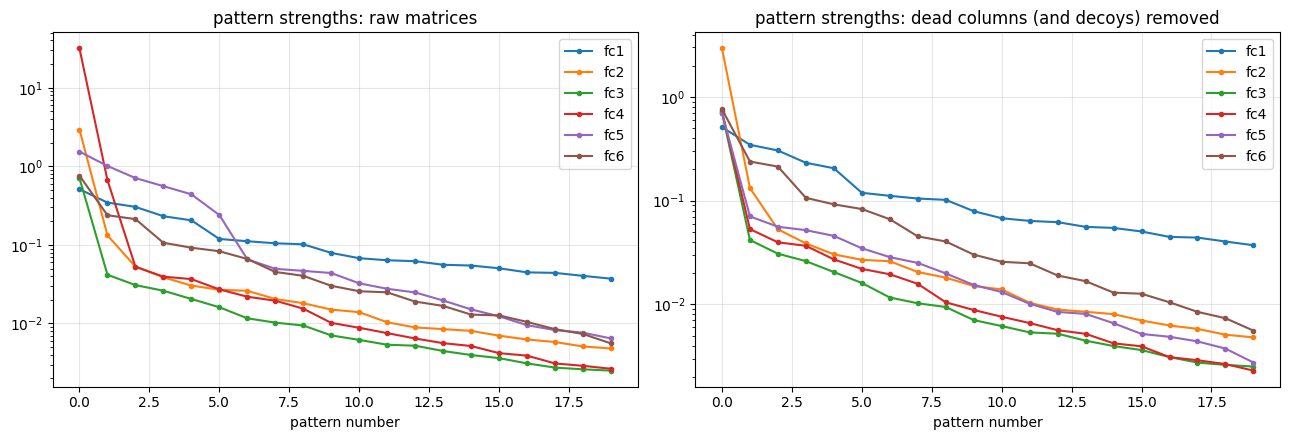

In [4]:
masked, msvd = {}, {}
print(f"{'layer':6} {'raw s1':>8} {'raw s2':>7} {'raw ratio':>9} | {'masked s1':>9} {'masked s2':>9} {'masked ratio':>12}")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name in LAYERS:
    W = weights[f"{name}.weight"].astype(np.float64)
    Wm = W.copy()
    if name in PREV:
        Wm[:, dead[PREV[name]]] = 0.0
    masked[name] = Wm
    s_raw = np.linalg.svd(W, compute_uv=False)
    msvd[name] = np.linalg.svd(Wm)
    s_m = msvd[name][1]
    print(f"{name:6} {s_raw[0]:8.3f} {s_raw[1]:7.3f} {s_raw[0]/s_raw[1]:8.1f}x | {s_m[0]:9.3f} {s_m[1]:9.3f} {s_m[0]/s_m[1]:11.1f}x")
    axes[0].plot(s_raw[:20], marker="o", ms=3, label=name)
    axes[1].plot(s_m[:20], marker="o", ms=3, label=name)
for ax, t in zip(axes, ["raw matrices", "dead columns (and decoys) removed"]):
    ax.set_yscale("log"); ax.set_title(f"pattern strengths: {t}"); ax.set_xlabel("pattern number"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

In [5]:
print(f"baseline: NSE = {nse0:.4f}, bias = {bias0:+.5f}, floor = {np.isclose(preds0, FLOOR_VALUE, atol=1e-5).mean():.1%}\n")
print(f"{'layer':6} {'pattern':>7} {'strength':>9} {'NSE after':>10} {'bias after':>11} {'floor after':>12}")
for name in ["fc2", "fc3", "fc4", "fc5", "fc6"]:
    U, Sv, Vh = msvd[name]
    for k in [0, 1]:
        w_test = dict(weights)
        w_test[f"{name}.weight"] = (weights[f"{name}.weight"] - Sv[k] * np.outer(U[:, k], Vh[k])).astype(np.float32)
        r = score(w_test)
        print(f"{name:6} {k + 1:7d} {Sv[k]:9.3f} {r['NSE']:10.4f} {r['bias']:+11.5f} {r['floor']:12.1%}")

baseline: NSE = 0.6793, bias = +0.00321, floor = 28.2%

layer  pattern  strength  NSE after  bias after  floor after
fc2          1     2.936    -0.0220    -0.00851         0.0%
fc2          2     0.132     0.6867    +0.00261        28.3%
fc3          1     0.708    -0.2643    -0.01543        53.2%
fc3          2     0.042     0.6793    +0.00321        28.2%
fc4          1     0.725    -0.2681    -0.01548         0.2%
fc4          2     0.053     0.6793    +0.00321        28.2%
fc5          1     0.702    -0.2642    -0.01546         6.6%
fc5          2     0.071     0.6793    +0.00321        28.2%
fc6          1     0.761    -0.0027    -0.00855         0.0%
fc6          2     0.239     0.6682    +0.00323         0.1%


Now the earlier notebook's key experiment. It took the top pattern of the **raw** fc4 matrix (the decoy) and kept only the
part that reads from live fc3 units. Here is what that edit actually is.

In [6]:
W4 = weights["fc4.weight"].astype(np.float64)
U, Sv, Vh = np.linalg.svd(W4)
read_live = Vh[0].copy(); read_live[dead["fc3"]] = 0.0
part = Sv[0] * np.outer(U[:, 0], read_live)

row_size = np.linalg.norm(part, axis=1)
on_decoy_rows = np.zeros(56, bool); on_decoy_rows[np.where(decoy["fc4"])[0]] = True
print(f"share of the edit that sits on the 20 decoy rows (18-37): {(row_size[on_decoy_rows]**2).sum() / (row_size**2).sum():.6f}")
print(f"size of the edit on each of those rows: {np.unique(np.round(row_size[on_decoy_rows], 4))}")
print(f"direction it reads vs fc4's top *masked* (load-bearing) pattern: cosine = {S.cos_sim(read_live, msvd['fc4'][2][0]):.4f}")
print(f"size of edit = {np.linalg.norm(part):.3f}  vs size of fc4's live part = {np.linalg.norm(masked['fc4']):.3f} "
      f"({np.linalg.norm(part) / np.linalg.norm(masked['fc4']):.0%})")

w_test = dict(weights); w_test["fc4.weight"] = (W4 - part).astype(np.float32)
r = score(w_test)
print(f"\nafter the edit: NSE = {r['NSE']:.4f}, bias = {r['bias']:+.5f}")
q = S.forward(w_test, X)
new_floor = q.min()
print(f"hours within 1e-6 of the OLD floor {FLOOR_VALUE}: {np.isclose(q, FLOOR_VALUE, atol=1e-6).mean():.1%}")
print(f"new lowest prediction = {new_floor:.8f} (moved by {new_floor - FLOOR_VALUE:+.1e}); "
      f"hours within 1e-6 of it: {np.isclose(q, new_floor, atol=1e-6).mean():.1%}")

share of the edit that sits on the 20 decoy rows (18-37): 1.000000
size of the edit on each of those rows: [0.0636]
direction it reads vs fc4's top *masked* (load-bearing) pattern: cosine = 0.9996
size of edit = 0.285  vs size of fc4's live part = 0.730 (39%)

after the edit: NSE = 0.6816, bias = +0.00073
hours within 1e-6 of the OLD floor 0.00782154: 1.0%
new lowest prediction = 0.00781807 (moved by -3.5e-06); hours within 1e-6 of it: 26.0%


## What I found

- **The 47x spike in fc4 was the decoy.** With dead columns removed, fc4's ratio falls from 47x to about 14x, and its top
  strength from 31.6 to 0.73, the same size as fc3's (0.71) and fc5's (0.70).
- **A dominant first pattern is normal for this network, not a sign of tampering.** After masking, fc2, fc3, fc4 and fc5
  *all* have a first pattern 10-22x stronger than the second (fc5's was hidden behind its own decoy, 1.5x raw -> 10x masked).
  This is how a deep, thin ReLU network carries its one main signal (wetness) from layer to layer. So the SVD-ratio screen
  cannot single out any layer.
- **Every masked top pattern is load-bearing.** Removing it from fc2-fc6 drives NSE to between -0.27 and 0. Removing the
  second pattern does nothing in fc3-fc5. Two exceptions: in fc2 it gives a small bias reduction (+0.00321 -> +0.00261; Stage 10
  shows this is the unit-36 rescaling decoy), and in fc6 it leaves the bias unchanged but lowers NSE (0.6793 -> 0.6682) and
  moves the floor (only 0.1% of hours stay near the old value), so fc6's second pattern is live but not a bias carrier.
- **The earlier "live-unit part" edit was not a hidden signal inside the decoy.** It subtracts fc4's own main read direction
  (cosine 0.9996 with the load-bearing pattern) from exactly the 20 decoy rows, by the same amount on each row. Its size (0.28)
  is about 39% of fc4's entire live part, so it is a large structural cut, not a small surgical fix. It lowers the bias
  (+0.00321 -> +0.00073), but that only shows that turning fc4's main signal down in 20 units shifts the output.
- **The floor was not actually freed.** The earlier notebook reported the floor share dropping from ~26% to ~1%, but that
  counted hours within 1e-6 of the *old* value. The floor simply moved down by 3.5e-6 (to 0.0078181); about 26% of hours
  still sit on the new value. The flatline mechanism is untouched by that edit.
- **Conclusion: the earlier evidence for fc4 does not hold up.** The question of which layer holds the real edit is open
  again, and needs tests that do not rely on whole-matrix statistics.

**Caveat:** none of this proves fc4 is innocent. It only shows the evidence used so far cannot tell the layers apart.

**Next:** weight forensics that look for an edit inside the live part of each matrix, causal tests of how small a repair each
layer allows, and probing for the direction the leak travels along.

---
# Stage 04 — Weight forensics: the fingerprint of training, and where it is broken

**Goal: find an edit inside the *live* part of the weights, using a property that training leaves behind and a hand edit would break.**

Two facts about how this model was trained give us a fingerprint:

- **Weight decay.** Training pulled every unused weight towards zero: weights attached to dead units sit at 1e-20 or smaller.
- **Balance.** With weight decay, a ReLU unit ends training with its incoming weights (plus bias) and its outgoing weights of
  about the same size. Why: a ReLU unit's output can be scaled up by k on the way in and down by k on the way out without
  changing any prediction, and weight decay settles on the cheapest choice, which is the balanced one.

A later hand edit to one weight matrix would change the size of that matrix's rows and columns but not their partners in the
neighbouring matrices, so it should show up as units that are out of balance on exactly one side.

**Technical test:** per-unit norm balance (incoming row + bias vs outgoing column, decoys masked), plus a check of the one
unit that is wildly out of balance.

1. **Confirm the weight-decay fingerprint** on dead units.
2. **Compute in/out balance** for every hidden unit and list the units that are off by more than 1.5x; for fc6, list every
   outlier with its squared excess, to show which rows carry the extra weight.
3. **Test fc2 unit 36**, the extreme outlier: rescale it back to balance, check whether any prediction changes, and redo
   fc1's balance (fc1's outgoing weights are fc2's columns, which unit 36 inflates).
4. **Redo fc2's SVD** after rebalancing, since unit 36 dominated it.

In [7]:
def unmask_decoys(name):
    W = weights[f"{name}.weight"].astype(np.float64).copy()
    if name in decoy: W[decoy[name]] = 0.0
    return W

print("weight-decay fingerprint: largest |weight| attached to a dead unit (decoy blocks excluded)")
for name, p in PREV.items():
    cols = np.abs(unmask_decoys(name)[:, dead[p]])
    print(f"  {name}: columns from dead {p} units: max {cols.max() if cols.size else 0:.1e}")

ALL = LAYERS + ["out"]
balance, norms = {}, {}
print(f"\n{'unit layer':10} {'median in/out':>14}   units out of balance (>1.5x): unit(in, out, ratio)")
for i, name in enumerate(LAYERS):
    nxt = ALL[i + 1]
    W_in = unmask_decoys(name); b = weights[f"{name}.bias"].astype(np.float64)
    W_out = unmask_decoys(nxt) if nxt != "out" else weights["out.weight"].astype(np.float64)
    n_in = np.sqrt((W_in ** 2).sum(axis=1) + b ** 2); n_out = np.sqrt((W_out ** 2).sum(axis=0))
    ratio = n_in / np.maximum(n_out, 1e-12)
    big = np.maximum(n_in, n_out) > 0.03                      # ignore near-zero (decayed) units
    balance[name], norms[name] = ratio, (n_in, n_out, big)
    idx = np.where(big & ((ratio > 1.5) | (ratio < 1 / 1.5)))[0]
    odd = [f"{j}({n_in[j]:.3f}, {n_out[j]:.3f}, {ratio[j]:.2f})" for j in idx]
    shown = odd if len(odd) <= 8 else [f"{len(odd)} units: " + ", ".join(str(j) for j in idx)]
    print(f"{name:10} {np.median(ratio[big]):14.2f}   {', '.join(shown) if odd else '-'}")

weight-decay fingerprint: largest |weight| attached to a dead unit (decoy blocks excluded)
  fc2: columns from dead fc1 units: max 0.0e+00
  fc3: columns from dead fc2 units: max 1.6e-16
  fc4: columns from dead fc3 units: max 3.7e-09
  fc5: columns from dead fc4 units: max 6.5e-11
  fc6: columns from dead fc5 units: max 1.4e-05

unit layer  median in/out   units out of balance (>1.5x): unit(in, out, ratio)
fc1                  0.30   43 units: 0, 1, 2, 3, 4, 5, 6, 8, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 24, 25, 26, 27, 28, 29, 31, 32, 33, 34, 36, 37, 39, 40, 41, 42, 43, 45, 49, 50, 51, 52, 53, 54
fc2                  1.02   36(2.860, 0.011, 269.48)
fc3                  0.98   -
fc4                  1.03   -
fc5                  0.93   1(0.105, 0.240, 0.44), 10(0.006, 0.068, 0.09), 29(0.057, 0.097, 0.58), 41(0.062, 0.101, 0.61), 47(0.046, 0.131, 0.35), 51(0.031, 0.145, 0.21)
fc6                  1.34   15 units: 4, 9, 20, 24, 28, 29, 30, 32, 35, 41, 43, 48, 49, 50, 55


fc6 has 15 out-of-balance units, so before going on I list all of them, with the quantity that matters for an additive edit:
the **squared excess** in² − out² (how much extra squared weight the row carries), and the unit's output weight (positive =
adds water).

In [8]:
ni6, no6, big6 = norms["fc6"]
w_out6 = weights["out.weight"][0].astype(np.float64)
odd6 = np.where(big6 & (balance["fc6"] > 1.5))[0]
excess6 = ni6 ** 2 - no6 ** 2
print(f"{'fc6 unit':>8} {'in':>6} {'out':>6} {'ratio':>6} {'excess in^2-out^2':>18} {'output weight':>14}")
for j in odd6:
    print(f"{j:8d} {ni6[j]:6.3f} {no6[j]:6.3f} {balance['fc6'][j]:6.2f} {excess6[j]:18.4f} {w_out6[j]:+14.3f}")
R6_sel = [int(j) for j in odd6 if excess6[j] > 0.02]
print(f"\nrows with squared excess > 0.02: {R6_sel} ({len(R6_sel)} rows)")
print(f"their share of the total squared excess of all {len(odd6)} out-of-balance rows: "
      f"{excess6[R6_sel].sum() / excess6[odd6].sum():.1%}")
print(f"incoming size of those rows: {ni6[R6_sel].min():.3f}-{ni6[R6_sel].max():.3f}; "
      f"of the other {len(odd6) - len(R6_sel)}: {ni6[[j for j in odd6 if j not in R6_sel]].max():.3f} or less")

C5m = unmask_decoys("fc6")
cols = {j: C5m[:, j] for j in [10, 47, 51]}
print("\ncosines between the fc6 columns of fc5 units 10, 47, 51:",
      ", ".join(f"{a}-{b}: {S.cos_sim(cols[a], cols[b]):.2f}" for a, b in [(10, 47), (10, 51), (47, 51)]))

fc6 unit     in    out  ratio  excess in^2-out^2  output weight
       4  0.203  0.096   2.12             0.0322         +0.096
       9  0.032  0.016   1.99             0.0007         -0.016
      20  0.193  0.080   2.41             0.0308         +0.080
      24  0.057  0.017   3.44             0.0030         -0.017
      28  0.063  0.030   2.08             0.0031         -0.030
      29  0.037  0.016   2.26             0.0011         -0.016
      30  0.204  0.099   2.07             0.0318         +0.099
      32  0.171  0.071   2.40             0.0243         +0.071
      35  0.243  0.123   1.97             0.0439         +0.123
      41  0.220  0.103   2.13             0.0376         +0.103
      43  0.201  0.087   2.31             0.0329         +0.087
      48  0.205  0.095   2.17             0.0332         +0.095
      49  0.052  0.014   3.80             0.0026         +0.014
      50  0.221  0.096   2.29             0.0395         +0.096
      55  0.043  0.018   2.40           

fc2 unit 36 is 270x out of balance: huge incoming weights, tiny outgoing weights. If that is a rescaling, dividing its incoming
weights and bias by k and multiplying its outgoing weights by k (k = sqrt(270), about 16.4) should leave every prediction unchanged.

In [9]:
W2, b2, W3 = (weights[k].astype(np.float64) for k in ["fc2.weight", "fc2.bias", "fc3.weight"])
n_in36 = np.sqrt((W2[36] ** 2).sum() + b2[36] ** 2); n_out36 = np.linalg.norm(W3[:, 36])
k36 = np.sqrt(n_in36 / n_out36)
print(f"fc2 unit 36: incoming {n_in36:.3f} (median unit {np.median(np.linalg.norm(W2, axis=1)):.3f}), outgoing {n_out36:.4f}; "
      f"bias/weight ratio {abs(b2[36]) / np.linalg.norm(W2[36]):.3f} (other units: median {np.median(np.abs(b2) / np.linalg.norm(W2, axis=1)):.3f})")

w_rebal = dict(weights)
W2r, b2r, W3r = W2.copy(), b2.copy(), W3.copy()
W2r[36] /= k36; b2r[36] /= k36; W3r[:, 36] *= k36
w_rebal.update({"fc2.weight": W2r.astype(np.float32), "fc2.bias": b2r.astype(np.float32), "fc3.weight": W3r.astype(np.float32)})
print(f"rescale factor k = {k36:.2f}; largest change in any prediction after rebalancing: {np.abs(S.forward(w_rebal, X) - preds0).max():.1e}")

# fc1's balance is measured against fc2's columns, which row 36 inflates; redo it with unit 36 rebalanced
n_in1, _, big1 = norms["fc1"]
for label, W2x in [("unit 36 rebalanced", W2r), ("fc2 row 36 left out", np.delete(W2, 36, axis=0))]:
    r1 = n_in1 / np.linalg.norm(W2x, axis=0)
    print(f"fc1 balance with {label:20}: median in/out {np.median(r1[big1]):.2f}, "
          f"units beyond 1.5x: {int((big1 & ((r1 > 1.5) | (r1 < 1 / 1.5))).sum())}")

s_before = np.linalg.svd(W2, compute_uv=False)
U2r, S2r, V2r = np.linalg.svd(W2r)
print(f"\nfc2 strengths before: {np.round(s_before[:4], 3)}  ratio {s_before[0] / s_before[1]:.1f}x")
print(f"fc2 strengths after : {np.round(S2r[:4], 3)}  ratio {S2r[0] / S2r[1]:.1f}x")
for k in [1, 2]:
    w_test = dict(w_rebal); w_test["fc2.weight"] = (W2r - S2r[k] * np.outer(U2r[:, k], V2r[k])).astype(np.float32)
    r = score(w_test)
    print(f"  remove rebalanced fc2 pattern {k + 1} (strength {S2r[k]:.3f}): NSE {r['NSE']:.4f}, bias {r['bias']:+.5f}")

fc2 unit 36: incoming 2.860 (median unit 0.093), outgoing 0.0106; bias/weight ratio 0.089 (other units: median 0.112)
rescale factor k = 16.42; largest change in any prediction after rebalancing: 6.0e-08
fc1 balance with unit 36 rebalanced  : median in/out 1.15, units beyond 1.5x: 0
fc1 balance with fc2 row 36 left out : median in/out 1.18, units beyond 1.5x: 0

fc2 strengths before: [2.936 0.132 0.053 0.039]  ratio 22.2x
fc2 strengths after : [0.739 0.056 0.041 0.037]  ratio 13.1x
  remove rebalanced fc2 pattern 2 (strength 0.056): NSE 0.6793, bias +0.00321
  remove rebalanced fc2 pattern 3 (strength 0.041): NSE 0.6793, bias +0.00321


## What I found

- **The weight-decay fingerprint holds everywhere except the decoys.** Weights reading dead units are 4e-9 or smaller in fc3,
  fc4 and fc5, and at most about 1e-5 in fc6. So training did use weight decay, and the balance test is meaningful.
- **fc3 and fc4 are in near-perfect balance** (median in/out about 1.0, no outliers at all). Nothing was added to fc4.weight
  or fc3.weight that changed the size of any row or column.
- **fc2 unit 36 is a third decoy, a rescaling one.** Its incoming weights and bias were multiplied by about 16 and its outgoing
  weights divided by about 16. Undoing that changes no prediction (max difference about 6e-8, float rounding). This is what
  made fc2's top pattern 2.94 and its ratio 22x. After rebalancing, fc2's spectrum (0.74, 0.056, 0.041, ...) looks like every
  other layer, and its 2nd and 3rd patterns are completely inert.
- **fc1's apparent imbalance (median 0.30, 43 units) is a side effect of the same decoy, not a property of the input layer.**
  fc1's outgoing weights are fc2's columns, and the ×16 row 36 inflates every one of them. With unit 36 rebalanced, or row 36
  left out, fc1's median moves to 1.15-1.18 with no unit beyond 1.5x (printed above). So fc1 is balanced too.
- **The only one-sided imbalance in the live network is around fc6.weight.** fc5 units 1, 10, 29, 41, 47, 51 have *outgoing*
  weights (fc6 columns) 1.6x to 11x larger than their incoming weights (unit 10 is the extreme at 11x; 29 and 41 are only
  1.6-1.7x). On the other side, 15 fc6 units have *incoming* weights (fc6 rows) more than 1.5x their outgoing weights. Nine of
  them (4, 20, 30, 32, 35, 41, 43, 48, 50) are large units (incoming size 0.17-0.24) that all add water, and together they carry
  about 96% of the squared excess. The other six (9, 24, 28, 29, 49, 55) have higher *ratios* (up to 3.8x for unit 49) but are
  tiny units (incoming size 0.06 or less), so their absolute excess is small; five of the six have negative output weights.
  An additive edit u·vᵀ shows up as squared excess, not as a ratio, so **"the nine rows" in later stages means the rows with
  squared excess above 0.02**. Both sides of the imbalance point at the same matrix: fc6.weight has extra mass in a block of
  columns and a block of rows. That is the shape a rank-1 addition u·vᵀ (u over those fc6 rows, v over those fc5 columns)
  would leave.
- The fc6 columns of fc5 units 10, 47 and 51 are almost parallel (cosines printed above, as Agent A first noticed), all
  pointing into roughly the same set of fc6 units. Columns of a trained matrix are not normally that aligned.

**Caveat:** imbalance shows where weights were *changed*, not that the change causes the extra water. Agent A reported
(not recomputed here) that removing the parallel-column component alone only moves the bias from +0.00321 to +0.00314. The
fc6 imbalance is also spread more evenly (median 1.34, and 6 small rows beyond the nine) than a single clean rank-1 edit would
predict.

**Next:** test whether a small edit in fc6 can remove the extra water *specifically*, compared with other layers.

---
# Stage 05 — A negative result: removing the out-of-balance block of fc6

**Goal: test the most literal reading of Stage 04, that the planted edit is exactly the block of fc6.weight where the
out-of-balance rows and columns meet.**

Stage 04 found fc6 rows (units 4, 20, 30, 32, 35, 41, 43, 48, 50, the nine with squared excess above 0.02) with too much
incoming weight and fc5 columns (units 1, 10, 29, 41, 47, 51) with too much outgoing weight. If someone added u·vᵀ to fc6, the added mass should be concentrated where those
rows and columns cross. The obvious test is to take that 9x6 sub-block, find its strongest pattern, and subtract it.

**Technical test:** rank-1 sub-block removal.

1. **Cut out the 9x6 sub-block** and run an SVD on it. Check whether it is unusually close to rank 1 by comparing with 500
   random 9x6 blocks of live fc6 rows and fc5 columns.
2. **Subtract its top pattern** at several strengths (and also *add* it, as a sign check), and re-score.

In [10]:
R6 = [4, 20, 30, 32, 35, 41, 43, 48, 50]          # fc6 rows with squared excess > 0.02 (Stage 04)
assert R6 == R6_sel
C5 = [1, 10, 29, 41, 47, 51]                      # fc5 units with too much outgoing weight (Stage 04)
W6 = weights["fc6.weight"].astype(np.float64)
Ub, Sb, Vb = np.linalg.svd(W6[np.ix_(R6, C5)])
print(f"sub-block strengths: {np.round(Sb, 3)}   ratio s1/s2 = {Sb[0] / Sb[1]:.1f}")

live5 = np.where(acts0["fc5"].max(axis=0) > 0)[0]; live6 = np.where(acts0["fc6"].max(axis=0) > 0)[0]
rng = np.random.default_rng(0)
null = []
for _ in range(500):
    sv = np.linalg.svd(W6[np.ix_(rng.choice(live6, 9, replace=False), rng.choice(live5, 6, replace=False))], compute_uv=False)
    null.append(sv[0] / sv[1])
print(f"random 9x6 live blocks: median ratio {np.median(null):.1f}, 95th percentile {np.percentile(null, 95):.1f}")
print(f"signs of the block's read pattern over fc5 units {C5}: {np.sign(Vb[0] * np.sign(Vb[0][0])).astype(int)}")

print(f"\n{'amount subtracted':>18} {'NSE':>7} {'bias':>9}")
for t in [-0.5, -0.25, 0.25, 0.5, 1.0]:
    D = np.zeros_like(W6); D[np.ix_(R6, C5)] = t * Sb[0] * np.outer(Ub[:, 0], Vb[0])
    w_test = dict(weights); w_test["fc6.weight"] = (W6 - D).astype(np.float32)
    r = score(w_test)
    print(f"{t:18.2f} {r['NSE']:7.4f} {r['bias']:+9.5f}")
print(f"(baseline: NSE {nse0:.4f}, bias {bias0:+.5f})")

sub-block strengths: [0.316 0.051 0.024 0.012 0.004 0.001]   ratio s1/s2 = 6.2
random 9x6 live blocks: median ratio 3.0, 95th percentile 6.0
signs of the block's read pattern over fc5 units [1, 10, 29, 41, 47, 51]: [ 1 -1  1  1 -1 -1]

 amount subtracted     NSE      bias
             -0.50  0.6885  +0.00171
             -0.25  0.6849  +0.00237
              0.25  0.6701  +0.00435
              0.50  0.6578  +0.00550
              1.00  0.6244  +0.00779
(baseline: NSE 0.6793, bias +0.00321)


## What I found

- **The block is close to rank 1** (strengths 0.316 vs 0.051, ratio 6.2), just above the 95th percentile of random 9x6 blocks
  (about 6.0). Within each column the nine rows share one sign, except the small fc5-unit-29 column, whose entries are mixed.
  So it carries a structured, mostly single pattern, though the evidence that it is unusual is marginal.
- **But subtracting it makes the problem worse.** Removing a quarter of it raises the bias from +0.00321 to +0.00435;
  removing all of it raises it to +0.00779 and drops NSE to 0.62. Going the other way (adding *more* of the pattern) lowers the
  bias (+0.00171 at -0.5) and even raises NSE.
- So the literal reading of Stage 04 is wrong: this block is not "the extra water". Either the block is part of the model's
  normal flow pathway that happens to be large, or the planted edit overlaps it with a different shape and sign. In other words,
  imbalance tells us *where* weights look disturbed, but not the direction of the edit.
- A likely reason: the block's largest column is fc5 unit 1 (entries -0.06 to -0.09). Stage 08 shows that a reconstruction
  which leaves unit 1 out *does* remove the extra water; Agent E reported (not recomputed here) that including unit 1 overshoots.

**Caveat:** in the coordinator's first version of this check, the balance calculation did not mask fc5's 0.2 decoy columns.
Here the rows and columns are taken from Stage 04, which does mask them, and the block itself contains no decoy entries
(columns 1, 10, 29, 41, 47, 51 are all live). The conclusion is the same.

**Next:** stop guessing the shape of the edit from statistics and measure, layer by layer, what small edits can do.

---
# Stage 06 — How small an edit in each layer is enough to remove the extra water?

**Goal: test whether "the bias can be fixed by editing layer X" says anything about where the real edit is.**

The scoring rewards a repair that removes the extra water, keeps accuracy, and is no bigger than the original tampering.
If one layer allowed a much smaller fix than the others, that would be a clue. So for every layer I computed the smallest
change to its weights that brings the average bias to the clean level.

**Technical test:** linearised minimum-norm repair. The gradient g of the mean prediction with respect to a layer's weights
says which small change moves the average output fastest. Stepping against g is the smallest edit (in Frobenius norm) that
lowers the mean, to first order.

1. **Backpropagate** the mean prediction to every layer's weight matrix (plain numpy, no autograd).
2. **Step along -g/|g|** with a size t found by bisection so that the bias over all hours becomes +0.00015 (about the clean
   model's value on this data).
3. **Re-score** with a full forward pass: edit size, NSE, the share of hours stuck on the lowest prediction (wherever the
   floor has moved to, since Stage 03 showed that counting near the *old* floor value is misleading), and how close g is to rank 1.

In [11]:
def mean_pred_grads(w, X):
    """d mean(prediction) / d W for every hidden layer, by manual backprop."""
    hs, zs, h = [X.astype(np.float64)], [], X.astype(np.float64)
    for name in LAYERS:
        z = h @ w[f"{name}.weight"].T + w[f"{name}.bias"]
        zs.append(z); h = np.maximum(z, 0); hs.append(h)
    d = np.tile(w["out.weight"].astype(np.float64), (len(X), 1)) / len(X)    # d mean / d h6
    grads = {}
    for i in range(len(LAYERS) - 1, -1, -1):
        name = LAYERS[i]
        d = d * (zs[i] > 0)
        grads[name] = d.T @ hs[i]
        d = d @ w[f"{name}.weight"]
    return grads

grads = mean_pred_grads(weights, X)
TARGET_BIAS = 0.00015
repairs = {}
print(f"{'layer':6} {'edit size':>9} {'NSE after':>10} {'bias after':>11} {'stuck':>7} {'g s2/s1':>8}")
for name in ["fc2", "fc3", "fc4", "fc5", "fc6"]:
    g = grads[name]; ghat = g / np.linalg.norm(g)
    sv = np.linalg.svd(g, compute_uv=False)
    def bias_at(t):
        w_test = dict(weights); w_test[f"{name}.weight"] = (weights[f"{name}.weight"] - t * ghat).astype(np.float32)
        return score(w_test)
    lo, hi = 0.0, 0.05
    while bias_at(hi)["bias"] > TARGET_BIAS:
        hi *= 2
    for _ in range(40):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if bias_at(mid)["bias"] > TARGET_BIAS else (lo, mid)
    r = bias_at(hi); repairs[name] = hi * ghat
    print(f"{name:6} {hi:9.3f} {r['NSE']:10.4f} {r['bias']:+11.5f} {r['stuck']:7.1%} {sv[1] / sv[0]:8.3f}")

layer  edit size  NSE after  bias after   stuck  g s2/s1


fc2        0.130     0.6722    +0.00015   29.3%    0.018


fc3        0.035     0.6746    +0.00015   25.9%    0.000


fc4        0.131     0.6766    +0.00015   26.0%    0.001


fc5        0.106     0.6856    +0.00015   26.1%    0.028


fc6        0.058     0.6918    +0.00015   26.2%    0.206


## What I found

- **Every layer can be "fixed" by a tiny edit.** Bringing the bias to the clean level needs an edit of size about 0.035
  (fc3) to 0.13 (fc2, fc4), and in every case NSE stays at 0.67-0.69. fc6 and fc5 even *raise* NSE slightly.
- **The gradient is almost exactly rank 1 in every layer** (second singular value at most a few percent of the first, except
  fc6), and its read direction is just the layer's average activation. All these fixes do the same thing: turn down the one
  main signal a little.
- **None of them frees the floor** where it starts: fixes in fc3-fc6 keep about 25% of hours stuck on one value and only move
  that value down. The fc2 fix slightly *increases* the stuck share, because turning fc2 down switches more hours off.
- **Agent B's fuller version agrees** (reported by Agent B, not recomputed here). Fitting a rank-1 repair by gradient descent on the error (not just the mean) works in
  every layer with NSE within 2%. No layer's repair removes the floor-hour excess (about +0.0019 on 25% of hours). Repairs in
  fc2 always push *more* hours onto the floor (35%), even when the gradient is allowed to leak through switched-off units
  (a "leaky" stand-in for ReLU), so there is no functional sign of an edit in fc2.
- So **a bias fix cannot localise the edit.** This matches Stage 07 and is the core reason the earlier fc4 argument fails:
  "removing something in fc4 fixes the bias" is equally true of fc2, fc3, fc5 and fc6.

**Caveat:** these are the smallest edits that fix the *average*. The real tampering was presumably targeted (the overview
says it fires "under certain circumstances"), so its true size and shape could be quite different.

**Next:** look for a layer where a small edit does something *specific* rather than a uniform turn-down.

---
# Stage 07 — What does each layer represent, and can a "leak" direction be read out of it?

**Goal: find out whether any layer carries a separate signal that the extra water travels along, which would point to the edit.**

If someone planted an edit that adds water, it should push the activations along some direction in one layer. If the layers
carry several distinct signals (rain, soil moisture, season, evaporation...), a probe could find the one that lines up with
the edit. If they carry only one, probing has nothing to separate.

**Technical test:** activation PCA, linear probes, and a "dial down the main pattern" test in every layer.

1. **Measure how many independent signals each layer carries**: the share of activation variance in its first and second
   principal component (PC).
2. **Linear probes** (ridge regression from a layer's activations to a quantity): how well can each layer predict the
   observed flow, the model's error (prediction minus truth), and whether an hour is a floor hour?
3. **Shrink the top (masked) pattern by 20%** in each layer and see whether more than one layer can produce a clean-looking bias.

In [12]:
print(f"{'layer':6} {'PC1 share':>10} {'PC2 share':>10}")
for name in LAYERS:
    A = acts0[name] - acts0[name].mean(axis=0)
    ev = np.linalg.svd(A, compute_uv=False) ** 2
    print(f"{name:6} {ev[0] / ev.sum():10.3f} {ev[1] / ev.sum():10.3f}")

def ridge_r2(H, t, lam=1e-3):
    """Ridge probe R^2 on a fixed 70/30 time split (first 70% fit, last 30% scored)."""
    n = int(0.7 * len(t))
    H1 = np.c_[H, np.ones(len(H))]
    w = np.linalg.solve(H1[:n].T @ H1[:n] + lam * np.eye(H1.shape[1]), H1[:n].T @ t[:n])
    r = t[n:] - H1[n:] @ w
    return 1 - (r ** 2).sum() / ((t[n:] - t[n:].mean()) ** 2).sum()

floor_ind = np.isclose(preds0, FLOOR_VALUE, atol=1e-5).astype(float)
targets = {"observed flow": truth.astype(float), "model error": (preds0 - truth).astype(float), "floor hour": floor_ind}
print(f"\n{'probe R^2':14}" + "".join(f"{n:>7}" for n in LAYERS))
for tname, t in targets.items():
    print(f"{tname:14}" + "".join(f"{ridge_r2(acts0[n].astype(float), t):7.2f}" for n in LAYERS))

layer   PC1 share  PC2 share
fc1         0.545      0.136
fc2         1.000      0.000
fc3         1.000      0.000
fc4         0.996      0.004
fc5         0.970      0.028
fc6         0.927      0.062

probe R^2         fc1    fc2    fc3    fc4    fc5    fc6
observed flow    0.63   0.64   0.63   0.66   0.66   0.68
model error     -0.31  -0.27  -0.25  -0.26  -0.34  -0.30
floor hour       0.42   0.95   0.07   0.05   0.11   0.26


In [13]:
print(f"{'layer':6} {'shrink':>6} {'NSE':>7} {'bias':>9}")
for name in ["fc3", "fc4", "fc5", "fc6"]:
    U, Sv, Vh = msvd[name]                                    # masked SVD from Stage 03
    for frac in [0.2, 0.3]:
        w_test = dict(weights)
        w_test[f"{name}.weight"] = (weights[f"{name}.weight"] - frac * Sv[0] * np.outer(U[:, 0], Vh[0])).astype(np.float32)
        r = score(w_test)
        print(f"{name:6} {frac:6.0%} {r['NSE']:7.4f} {r['bias']:+9.5f}")
print(f"\nclean model's bias for reference: {cfg['train']['bias']:+.5f}")

layer  shrink     NSE      bias
fc3       20%  0.6711  -0.00016
fc3       30%  0.6293  -0.00189
fc4       20%  0.6711  -0.00016
fc4       30%  0.6293  -0.00189
fc5       20%  0.6715  -0.00014
fc5       30%  0.6305  -0.00186
fc6       20%  0.6747  +0.00096
fc6       30%  0.6433  -0.00017

clean model's bias for reference: +0.00017


## What I found

- **From fc2 onward the network carries essentially one signal.** The first PC holds 100% of the variance in fc2 and fc3,
  99.6% in fc4, 97% in fc5 and 93% in fc6 (fc1, which reads the raw inputs, is the exception: 55% and 14%). With one
  direction holding 97-100% of the variance, any linear probe from fc2-fc5 is reading essentially that one axis. Agent C
  reported (not recomputed here) that probes for rain totals, soil moisture, season and a temperature-based evaporation proxy
  all collapse onto the same "wetness" axis; the probes run above cover only flow, error and floor hours.
- **The model's error is not readable from any layer** (held-out probe R^2 below 0 everywhere, i.e. worse than guessing the
  average). There is no separate "extra water" signal that a linear probe can find. Observed flow is equally readable from
  every layer (R^2 0.63-0.68). Floor hours are almost perfectly readable from fc2 (0.95) and barely from fc3-fc5, which fits
  the floor being created by fc2 units switching off.
- **A bias fix is available in several layers.** Turning the main pattern down by 20% in fc3, fc4 or fc5 brings the bias to
  -0.00015 (about the clean +0.00017 in size) with NSE 0.67; fc6 needs about 30%. fc3 and fc4 give *identical* numbers (fc5 nearly so),
  because the same single signal passes through all three. So "removing pattern X fixes the bias" does not identify the layer by itself;
  any layer on the main pathway can do it.
- **fc6 is the one hidden layer past the input with extra structure.** Among fc2-fc6, once the decoys are masked and fc2's
  unit 36 is rebalanced, fc6 is the only layer whose live weights have more than one sizeable pattern (strengths 0.76, 0.24,
  0.21, against second strengths of 0.04-0.07 in fc3-fc5 and 0.056 in rebalanced fc2; fc2's raw 0.132 is the unit-36 decoy,
  Stage 04) and whose activations have a real second PC (6%). fc1 also has several sizeable patterns (0.51, 0.35; PC2 14%),
  but fc1 reads the raw inputs directly (a 72-hour rainfall window plus soil moisture at two depths, season, air temperature
  and sunlight), so several signals there are expected rather than suspicious. Agent C reported (not
  recomputed here) that fc6's third pattern lines up (cosine 0.68) with a vapour-pressure-deficit direction, an evaporation
  driver. Removing that pattern cuts bias to +0.00188 at unchanged NSE (Stage 10 reproduces this: 43.5% of the extra water).
  That is a weak lead: it fixes less than half of the extra water.

**Caveat:** probing can only see linear structure, and with near-1-D layers it has almost no resolving power. These results
neither support nor rule out a particular layer; they mainly show that the earlier fc4 argument does not single fc4 out.

**Next:** combine with the causal and forensic results to reach a verdict.

---
# Stage 08 — Activation SVD, and a weight-only reconstruction of the fc6 edit

**Goal: (a) check whether any direction in the hour-by-hour activations, rather than the weights, carries the extra water;
(b) rebuild the fc6 edit from the weight-decay fingerprint alone, without fitting to the data, and see what it does.**

Stage 07 showed the layers are nearly one-dimensional. Agent E tested this directly by ablating each principal component of
each layer's activations. E then used the balance rule from Stage 04 *quantitatively*: if a rank-1 edit u·xᵀ was added to fc6,
each fc6 column's excess size, and each fc6 row's excess size, tell us how big x and u must be. That gives an estimate of the
edit that uses no streamflow data at all, so its effect on the bias is a genuine test, not a fit.

**Technical test:** principal-component ablation, then weight-only rank-1 reconstruction.

1. **For every layer**, remove each of the first few principal components of the live activations (replace by its mean) and
   push the result through the rest of the network.
2. **Measure each fc6 row's and fc5 unit's imbalance** (squared norms, decoys masked). Rows with too much incoming weight
   define u. For each fc5 column, solve for how much of u has to be removed to restore its balance; this gives x.
3. **Subtract u·xᵀ from fc6** and score. Then look at *when* the removed water occurred (by flow decile).

In [14]:
def forward_from(w, layer, h):
    """Continue the forward pass from the activations h of `layer`."""
    for name in LAYERS[LAYERS.index(layer) + 1:]:
        h = S.relu(h @ w[f"{name}.weight"].T + w[f"{name}.bias"])
    return (h @ w["out.weight"].T + w["out.bias"])[:, 0]

print(f"{'layer':6} {'PC':>3} {'var %':>8} {'bias after':>11} {'NSE change':>11}")
for name in LAYERS:
    H = acts0[name].astype(np.float64); live = np.where(H.max(axis=0) > 0)[0]
    Hl = H[:, live]; mu = Hl.mean(axis=0)
    _, sv, Vt = np.linalg.svd(Hl - mu, full_matrices=False)
    var = 100 * sv ** 2 / (sv ** 2).sum()
    for k in range(4):
        Hf = H.copy(); Hf[:, live] = Hl - np.outer((Hl - mu) @ Vt[k], Vt[k])
        p = forward_from(weights, name, Hf)
        print(f"{name:6} {k + 1:3d} {var[k]:8.3f} {p.mean() - truth.mean():+11.5f} {S.nse(p, truth) - nse0:+11.4f}")
print("note: fc6 feeds the output linearly, so replacing an fc6 PC by its mean cannot change the mean prediction;\n"
      "      the fc6 bias column is +0.00321 by construction and carries no information.")

layer   PC    var %  bias after  NSE change
fc1      1   54.487    +0.00372     -0.6288
fc1      2   13.592    +0.00315     -0.0078
fc1      3   12.101    +0.00241     -0.0327


fc1      4    5.962    +0.00280     -0.0121


fc2      1   99.979    +0.00543     -0.7141
fc2      2    0.015    +0.00319     +0.0011
fc2      3    0.002    +0.00321     -0.0000
fc2      4    0.002    +0.00321     +0.0000
fc3      1  100.000    +0.00544     -0.7124
fc3      2    0.000    +0.00321     -0.0000


fc3      3    0.000    +0.00321     +0.0000
fc3      4    0.000    +0.00321     +0.0000
fc4      1   99.601    +0.00555     -0.7130
fc4      2    0.398    +0.00320     -0.0002
fc4      3    0.001    +0.00321     -0.0000


fc4      4    0.000    +0.00321     +0.0000
fc5      1   96.971    +0.00555     -0.7068
fc5      2    2.808    +0.00334     -0.0076
fc5      3    0.180    +0.00321     -0.0007
fc5      4    0.025    +0.00321     +0.0001
fc6      1   92.688    +0.00321     -0.6734
fc6      2    6.241    +0.00321     -0.0039
fc6      3    1.018    +0.00321     -0.0136
fc6      4    0.032    +0.00321     +0.0001
note: fc6 feeds the output linearly, so replacing an fc6 PC by its mean cannot change the mean prediction;
      the fc6 bias column is +0.00321 by construction and carries no information.


In [15]:
Wd = {k: v.astype(np.float64) for k, v in weights.items()}
M = Wd["fc6.weight"]
W5nd = Wd["fc5.weight"].copy(); W5nd[decoy["fc5"]] = 0.0                               # fc5 decoys masked
col_excess = (M ** 2).sum(axis=0) - ((W5nd ** 2).sum(axis=1) + Wd["fc5.bias"] ** 2)    # > 0: fc6 column too big
row_excess = ((M ** 2).sum(axis=1) + Wd["fc6.bias"] ** 2) - (Wd["out.weight"] ** 2).sum(axis=0)   # > 0: fc6 row too big

bad_rows = np.where(row_excess > 0.01)[0]
u = np.zeros(56); u[bad_rows] = np.sqrt(row_excess[bad_rows]); u /= np.linalg.norm(u)
cu = M.T @ u; disc = cu ** 2 - col_excess
x = np.where(disc >= 0, cu - np.sign(cu) * np.sqrt(np.maximum(disc, 0)), cu)            # smaller root restores balance
x[col_excess <= 0] = 0.0
x[1] = 0.0                       # fc5 unit 1 left out: Agent E found including it overshoots (see Stage 05)
delta_E = np.outer(u, x)

w_E = dict(weights); w_E["fc6.weight"] = (M - delta_E).astype(np.float32)
r = score(w_E); pE = S.forward(w_E, X)
v_E = x / np.linalg.norm(x)
print(f"fc6 rows with too much incoming weight: {bad_rows.tolist()}")
print(f"edit size {np.linalg.norm(delta_E):.3f}: NSE {nse0:.4f} -> {r['NSE']:.4f}, bias {bias0:+.5f} -> {r['bias']:+.5f}")
print("largest loadings of the read direction x (fc5 units):",
      ", ".join(f"{i}:{v_E[i]:+.2f}" for i in np.argsort(-np.abs(v_E))[:6]))

excess = preds0 - pE
dec = pd.qcut(pd.Series(truth).rank(method="first"), 10, labels=False)
print("\nwater removed by the edit, per observed-flow decile (driest -> wettest), mm/hr:")
print("  " + "  ".join(f"{excess[dec == d].mean():.4f}" for d in range(10)))
print(f"on floor hours: {excess[np.isclose(preds0, FLOOR_VALUE, atol=1e-5)].mean():.4f}")
print(f"correlation between the water removed and observed flow, hour by hour: {np.corrcoef(excess, truth)[0, 1]:.2f}")

fc6 rows with too much incoming weight: [4, 11, 20, 21, 30, 32, 35, 37, 41, 43, 46, 47, 48, 50]
edit size 0.207: NSE 0.6793 -> 0.6921, bias +0.00321 -> +0.00028
largest loadings of the read direction x (fc5 units): 51:+0.60, 47:+0.52, 10:+0.29, 41:-0.28, 45:+0.23, 25:+0.17

water removed by the edit, per observed-flow decile (driest -> wettest), mm/hr:
  0.0004  0.0006  0.0008  0.0018  0.0027  0.0033  0.0036  0.0040  0.0046  0.0074
on floor hours: 0.0003
correlation between the water removed and observed flow, hour by hour: 0.81


## What I found

- **No small activation direction in fc2-fc5 carries the extra water by itself.** Removing any of the small principal
  components there leaves the bias at +0.0032 (fc5's PC2 moves it the wrong way, to +0.0033). Only PC1, the main signal,
  moves it, and that destroys accuracy (NSE change about -0.71). In fc1 some components move the bias (PC3: +0.00241) but at a
  clear accuracy cost (-0.033).
- **The fc6 rows of this table are uninformative.** fc6 is followed only by the linear output layer, so replacing an fc6
  component by its mean leaves the *mean* prediction, and so the bias, unchanged by construction. They should not be read as
  evidence for or against fc6.
- The extra water is therefore not a separate, cleanly isolated activation pattern. Agent E reported (not recomputed here)
  that the eventual fc6 direction is spread over several fc5 components.
- **The weight-only reconstruction works.** Using nothing but the balance rule, the estimated fc6 edit (size about 0.21) brings
  the bias from +0.00321 to about +0.0003 and *raises* NSE from 0.679 to 0.692. Neither number was fitted. This is the
  strongest single piece of evidence for fc6.
- Its read direction x loads mostly on fc5 units 51, 47 and 10 (and 41 with the opposite sign). These are the quasi-constant
  "dry-state" units whose fc6 columns are near-parallel (Stage 04). The write side u sits on the same fc6 rows found in
  Stage 04 (4, 20, 30, 32, 35, 41, 43, 48, 50, plus 11, 21, 37, 46 and 47, whose squared excess passes this
  stage's lower 0.01 cut although their in/out ratio is under 1.5x).
- **Tension with the "dry hours" story:** the water this edit removes grows with flow (small in the driest decile, large in
  the wettest; hour-by-hour correlation with observed flow printed above). It is roughly a +10% scaling, not a dry-condition
  trigger, and it leaves most of the floor-hour excess in place.

**Caveat:** this read direction differs from the row-shrink direction m in Stage 09 (cosine about 0.6) and from Agent B's
fitted direction (about 0.7). All three agree on the layer (fc6) and on the rows (u), but not on the exact 56-dim direction.
Unit 1 had to be excluded by hand, which is a judgment call.

**Next:** test the other fc6 reading, shrinking the oversized rows along their own direction.

---
# Stage 09 — Following the fingerprint: do fc6's oversized rows hold the extra water?

**Goal: check whether undoing the fc6 imbalance from Stage 04 also removes the extra water, without tuning it to do so.**

Stage 05 showed that the fc6 *columns* that are out of balance are not the extra water. Agent B looked at the other side:
the nine fc6 *rows* (units 4, 20, 30, 32, 35, 41, 43, 48, 50) whose incoming weights are about twice as large as they should
be. All nine feed the output with a positive weight, so they are "water-adding" units. If someone inflated them, shrinking
them back to the size that training's balance rule predicts should remove extra water *on its own*. That would be an
independent check, because the amount of shrinking comes from the weights, not from the bias.

**Technical test:** balance-guided rank-1 row shrink.

1. **Check that the nine rows point the same way**: find their shared main direction m (an SVD of just those rows) and
   the cosine of each row with m.
2. **Shrink the rows along m** by a factor c: W6[R] <- W6[R] - (1 - c)·(W6[R]·m)·mᵀ. This is a rank-1 edit u·vᵀ with v = m,
   a direction in the space of fc5 activations.
3. **Read off the balance-implied c**, the value at which these rows' in/out ratio matches every other live fc6 unit, and
   see what the bias is there.

In [16]:
R6 = R6_sel                                                    # the nine rows with squared excess > 0.02 (Stage 04)
W6m = masked["fc6"]                                            # dead fc5 columns zeroed (Stage 03)
b6, w_out = weights["fc6.bias"].astype(np.float64), weights["out.weight"][0].astype(np.float64)
n_in6 = np.sqrt((W6m ** 2).sum(axis=1) + b6 ** 2); n_out6 = np.abs(w_out)
others = [j for j in np.where(acts0["fc6"].max(axis=0) > 0)[0] if j not in R6]
target_ratio = np.median(n_in6[others] / n_out6[others])
print(f"in/out ratio of the nine rows: {np.round(n_in6[R6] / n_out6[R6], 2)}; every other live fc6 unit: median {target_ratio:.2f}")
print(f"their output weights (all positive = add water): {np.round(w_out[R6], 3)}")

_, s_rows, V_rows = np.linalg.svd(W6m[R6])
m = V_rows[0] * np.sign(V_rows[0].sum())
print(f"\nstrengths of the nine rows together: {np.round(s_rows[:3], 3)}")
print(f"cosine of each row with their shared direction m: {np.round(np.abs(W6m[R6] @ m) / np.linalg.norm(W6m[R6], axis=1), 3)}")
print(f"cosine of m with fc6's main (load-bearing) read direction: {abs(m @ msvd['fc6'][2][0]):.3f}")
print("largest loadings of m (fc5 unit: value):", ", ".join(f"{i}:{m[i]:+.2f}" for i in np.argsort(-np.abs(m))[:10]))

print(f"\n{'c (kept)':>8} {'edit size':>9} {'NSE':>7} {'bias':>9} {'removed':>8} {'rows in/out':>12}")
shrink = {}
for c in [1.0, 0.8, 0.7, 0.6, 0.57, 0.5]:
    D = np.zeros((56, 56)); D[R6] = (1 - c) * np.outer(W6m[R6] @ m, m)
    w_test = dict(weights); w_test["fc6.weight"] = (weights["fc6.weight"] - D).astype(np.float32)
    r = score(w_test); shrink[c] = D
    ratio = np.median(np.sqrt(((W6m - D)[R6] ** 2).sum(axis=1) + b6[R6] ** 2) / n_out6[R6])
    print(f"{c:8.2f} {np.linalg.norm(D):9.3f} {r['NSE']:7.4f} {r['bias']:+9.5f} {(bias0 - r['bias']) / (bias0 - 0.00015):8.0%} {ratio:12.2f}")
w_test = dict(weights); w_test["fc6.weight"] = (weights["fc6.weight"] - shrink[0.57]).astype(np.float32)
print("('removed' = share of the extra water above the clean level +0.00015)")
print(f"c = 0.57: correlation between the water removed and observed flow: {np.corrcoef(preds0 - S.forward(w_test, X), truth)[0, 1]:.2f}")

in/out ratio of the nine rows: [2.12 2.41 2.07 2.4  1.97 2.13 2.31 2.17 2.29]; every other live fc6 unit: median 1.29
their output weights (all positive = add water): [0.096 0.08  0.099 0.071 0.123 0.103 0.087 0.095 0.096]

strengths of the nine rows together: [0.613 0.072 0.057]
cosine of each row with their shared direction m: [0.975 0.978 0.994 0.993 0.983 0.99  0.986 0.99  0.97 ]
cosine of m with fc6's main (load-bearing) read direction: 0.972
largest loadings of m (fc5 unit: value): 1:-0.37, 51:+0.23, 40:+0.23, 6:+0.22, 16:+0.22, 54:+0.22, 44:+0.21, 39:+0.21, 15:+0.21, 47:+0.21

c (kept) edit size     NSE      bias  removed  rows in/out


    1.00     0.000  0.6793  +0.00321       0%         2.17
    0.80     0.123  0.6881  +0.00191      43%         1.75
    0.70     0.184  0.6822  +0.00126      64%         1.54
    0.60     0.245  0.6695  +0.00062      85%         1.33
    0.57     0.263  0.6644  +0.00042      91%         1.27
    0.50     0.306  0.6501  -0.00003     106%         1.14
('removed' = share of the extra water above the clean level +0.00015)
c = 0.57: correlation between the water removed and observed flow: 0.82


## What I found

- **The nine rows are one pattern.** Each has a cosine of 0.97-0.99 with their shared direction m, and their combined
  strengths are 0.61 vs 0.07. That direction is essentially fc6's main "wetness" read direction (cosine 0.97). These units
  all add water to the output.
- **Shrinking them back to balance removes the extra water.** The rows' in/out ratio matches the other fc6 units (about 1.29)
  at c ≈ 0.57, and there the bias is +0.00042 (from +0.00321, so about 91% of the extra water removed). At c = 0.5 it is
  -0.00003. The size of the shrink was set by the balance rule, not by the bias, so the two independent measures agree.
- **The cost is accuracy.** NSE drops to 0.664 at c = 0.57, about 2.2% below the original, at the edge of the scoring's
  2% tolerance. At c = 0.7 (NSE 0.682) 64% of the extra water is gone.
- m is spread over many fc5 units: unit 1 dominates (magnitude 0.37) and the rest, including 51 and 47, sit around 0.2 each (printed
  above), so the "dry-state" units 47 and 51 are not special in m.
- This fits Agent B's more elaborate fit (rank-1 fc6 repair with a balance penalty). Its write vector u concentrates on these
  nine rows (91% of ‖u‖² for the shipped repair, checked in Stage 11; it has small nonzero entries elsewhere), and its best
  compromise reaches bias +0.00015 at NSE 0.682 with an edit of size 0.39 (Stage 11). Its consensus direction agrees with m
  at cosine 0.90, and the shipped edit's own read direction at 0.83 (Stage 11); Agent B reported (not recomputed here) that v differs between fits (cosine 0.72-0.97).

**Caveat:** a uniform "turn down the main signal" edit fixes the bias in any layer (Stage 06). What makes this one different
is that *which* rows and *how much* both come from the weight-decay fingerprint, and it is the only layer where that
fingerprint is broken. The repair still leaves the floor-hour excess (+0.002 on about 25% of hours) largely in place.

**Next:** compare with what the teammates concluded, then reach a verdict.

---
# Stage 11 — Verdict: the real edit is in fc6

**Goal: decide which layer holds the real edit, explain why, and package a recovered direction and a repaired matrix.**

**Verdict at this point: `fc6.weight`, with about 75-80% confidence.** The direction of the edit is only partly pinned
down. (Stages 12-15 add the leaderboard result and further tests, and Stage 16 updates this confidence.)

Why fc6, and why not the others. These lines of evidence are independent of each other:

| # | Evidence | fc6 | Other layers |
|---|---|---|---|
| 1 | **Weight-decay balance** (Stage 04): training leaves every unit with incoming ≈ outgoing size; a later edit breaks this on one side | Broken on *both* sides of fc6.weight: fc5 units 1, 10, 29, 41, 47, 51 (outgoing 1.6-11x too big) and 15 fc6 rows beyond 1.5x, of which nine large ones (4, 20, 30, 32, 35, 41, 43, 48, 50; incoming ~2x too big, near-parallel, all add water) hold 96% of the squared excess | fc3, fc4 balanced to ~5% with no outliers; fc2's only outlier is the function-preserving rescale of unit 36, and fc1 is balanced once that is undone |
| 2 | **Weight-only reconstruction** (Stage 08): rebuild the edit from the imbalance alone, no data | Bias +0.00321 -> +0.0003, NSE 0.679 -> 0.692, edit size 0.21 | Nothing to rebuild (no imbalance) |
| 3 | **Balance-guided shrink** (Stage 09): shrink the oversized rows to the size balance predicts | Removes ~90% of the extra water without being tuned to the bias | — |
| 4 | **Small-repair search** (Stage 06; Agents B and E) — *does not discriminate* | A min-norm edit reaches the clean bias (+0.00015) at NSE 0.692 | The same min-norm edit reaches +0.00015 in every one of fc2-fc5 too, at NSE 0.672-0.686 (Stage 06). Only Agent E's restricted projection-form fit (not shown here) plateaued at +0.0015-0.0019 in fc2-fc5; that reflects the restricted form, not the layer |
| 5 | **Decoys explained** (Stages 02-04) | — | fc4 ±5 block and fc5 0.2 block sit on dead inputs; fc2 unit 36 is a x16.4 rescale; all change no prediction |

Row 4 is listed for completeness: a bias repair is available in every layer, so it carries no weight in the verdict.
**The main white-box evidence is the balance test (rows 1-3)**; everything else either agrees with it or cannot tell the
layers apart.

**Why the earlier fc4 verdict was wrong** (Stage 03): fc4's 47x SVD spike is the ±5 decoy. The "small live part" that
appeared to fix the bias was a 39% cut of fc4's main signal on the decoy rows. It also did not free the floor; it moved it by
3.5e-6. **Why Sam's fc2 lead goes away** (Stages 04, 10): fc2's suspicious 2nd pattern is the rescaled unit 36. Once it is
rebalanced, which changes no prediction, every small fc2 pattern is inert.

**Technical test for this stage:**

1. **Load the chosen repair**: Agent B's balance-regularised rank-1 fc6 repair (`fc6_corrected.npy`) and its direction in
   fc5-activation space (`leak_direction.npy`), both copied next to this notebook.
2. **Score it against the alternatives**: Agent E's weight-only repair (Stage 08) and the balance-guided shrink (Stage 09).
3. **Compare the candidate directions** to show how well they agree.

In [18]:
fc6_corrected  = np.load("fc6_corrected.npy").astype(np.float32)      # Agent B, balance-regularised rank-1 repair
leak_direction = np.load("leak_direction.npy").astype(np.float64)     # Agent B, consensus read direction (fc5 space)
leak_direction /= np.linalg.norm(leak_direction)

W6_bug = weights["fc6.weight"].astype(np.float64)
candidates = {
    "B: balance-regularised (primary)": fc6_corrected.astype(np.float64),
    "E: weight-only (Stage 08)":        W6_bug - delta_E,
    "balance shrink c=0.57 (Stage 09)": W6_bug - shrink[0.57],
}
print(f"{'fc6 repair':34} {'edit size':>9} {'rank':>5} {'NSE':>7} {'NSE drop':>9} {'bias':>9} {'stuck':>6} {'corr(flow)':>10}")
print(f"{'(bugged model)':34} {0:9.3f} {'-':>5} {nse0:7.4f} {0:9.1%} {bias0:+9.5f} {score(weights)['stuck']:6.1%} {'-':>10}")
for label, W6c in candidates.items():
    D = W6_bug - W6c
    w_test = dict(weights); w_test["fc6.weight"] = W6c.astype(np.float32)
    r = score(w_test)
    sv = np.linalg.svd(D, compute_uv=False)
    removed = preds0 - S.forward(w_test, X)
    print(f"{label:34} {np.linalg.norm(D):9.3f} {int((sv > 1e-6 * sv[0]).sum()):5d} {r['NSE']:7.4f} "
          f"{(nse0 - r['NSE']) / nse0:9.1%} {r['bias']:+9.5f} {r['stuck']:6.1%} {np.corrcoef(removed, truth)[0, 1]:10.2f}")
print(f"clean model's bias for reference: {cfg['train']['bias']:+.5f}")
print("(corr(flow) = hour-by-hour correlation between the water a repair removes and the observed flow)")

uB = np.linalg.svd(W6_bug - fc6_corrected)[0][:, 0]
print(f"\nprimary repair's write vector u (unit length): {np.sum(uB[R6] ** 2):.0%} of |u|^2 on the nine rows {R6}; "
      f"{int((np.abs(uB) > 1e-3).sum())} rows above 1e-3; largest entry on a dead fc6 unit {np.abs(uB[dead['fc6']]).max():.1e}")

dirs = {"B consensus": leak_direction,
        "B edit's own read dir": np.linalg.svd(W6_bug - fc6_corrected)[2][0],
        "E weight-only": v_E, "Stage 09 m": m}
names = list(dirs)
print("\n|cos| between candidate directions (fc5-activation space):")
print(" " * 22 + "".join(f"{n[:12]:>14}" for n in names))
for a in names:
    print(f"{a:22}" + "".join(f"{S.cos_sim(dirs[a], dirs[b]):14.2f}" for b in names))
print("\nlargest loadings of the primary direction (fc5 unit: value):",
      ", ".join(f"{i}:{leak_direction[i]:+.2f}" for i in np.argsort(-np.abs(leak_direction))[:8]))
print(f"weight of the primary direction on dead fc5 units: {np.linalg.norm(leak_direction[dead['fc5']]):.3f}")

fc6 repair                         edit size  rank     NSE  NSE drop      bias  stuck corr(flow)
(bugged model)                         0.000     -  0.6793      0.0%  +0.00321  25.9%          -
B: balance-regularised (primary)       0.390     1  0.6817     -0.3%  +0.00015  25.9%       0.81
E: weight-only (Stage 08)              0.207     1  0.6921     -1.9%  +0.00028  26.2%       0.81
balance shrink c=0.57 (Stage 09)       0.263     1  0.6644      2.2%  +0.00042  26.0%       0.82
clean model's bias for reference: +0.00017
(corr(flow) = hour-by-hour correlation between the water a repair removes and the observed flow)

primary repair's write vector u (unit length): 91% of |u|^2 on the nine rows [4, 20, 30, 32, 35, 41, 43, 48, 50]; 38 rows above 1e-3; largest entry on a dead fc6 unit 6.0e-04

|cos| between candidate directions (fc5-activation space):
                         B consensus  B edit's own  E weight-onl    Stage 09 m
B consensus                     1.00          0.89          

### Writing the submission

The cell below builds `submission.csv` in the format `starter.py` describes (3,136 `fc_r_c` rows for the matrix plus 56 `dir_k`
rows for the direction, each duplicated under `pub_` and `prv_`). It only writes the file if `WRITE_SUBMISSION` is set to
`True`, and the writeup link must be pasted in first; a submission without it is rejected.

In [19]:
WRITE_SUBMISSION = False                                   # set to True to write submission.csv next to this notebook
WRITEUP_URL = "PASTE_YOUR_WRITEUP_LINK_HERE"               # Kaggle discussion link, required on every row

ids, vals = [], []
for r_ in range(56):
    for c_ in range(56):
        ids.append(f"fc_{r_}_{c_}"); vals.append(float(fc6_corrected[r_, c_]))
for k in range(56):
    ids.append(f"dir_{k}"); vals.append(float(leak_direction[k]))
ids = ["pub_" + i for i in ids] + ["prv_" + i for i in ids]
vals = vals + vals
sub = pd.DataFrame({"id": ids, "value": vals, "writeup_url": WRITEUP_URL})

example = pd.read_csv("submission_example.csv")
print(f"rows: {len(sub)} (example file: {len(example)}); same ids in same order: {list(sub['id']) == list(example['id'])}")
if WRITE_SUBMISSION:
    assert WRITEUP_URL.startswith("https://"), "paste the writeup link first"
    sub.to_csv("submission.csv", index=False)
    print("wrote submission.csv")
else:
    print("WRITE_SUBMISSION is False: nothing written")

rows: 6384 (example file: 6384); same ids in same order: True
WRITE_SUBMISSION is False: nothing written


## What I found

- **Layer: fc6.** It is the only layer where training's weight-decay fingerprint is broken in the live network, and two
  repairs built from that fingerprint remove most or all of the extra water without being fitted to it: Agent E's weight-only
  rank-1 edit (size 0.21, bias +0.0003, NSE up to 0.692) and the balance-guided row shrink (bias +0.0004). The primary fitted
  repair (Agent B) is exactly rank 1, size 0.39, with bias +0.00015 (the clean level) and NSE 0.682, inside the 2% tolerance.
- **The other layers are explained.** fc4 and fc5 hold inert decoys on dead inputs, fc2 holds an inert rescaling decoy, and fc3
  and fc4 are in perfect balance. Every layer *can* absorb the bias with a small edit (Stage 06), which is why bias-based
  arguments, including the earlier fc4 verdict, cannot identify the layer by themselves.
- **The direction is only partly pinned down.** The candidates agree on the layer and on the write side (the same fc6 rows),
  but not on the read side. Units 51 and 47 are among the top loadings of Agent B's and Agent E's directions, but in the
  Stage 09 direction m they are only about 0.2, like many others; unit 1 leads B and m but is excluded from E. Pairwise
  cosines are only about 0.6-0.9. The primary
  direction is Agent B's consensus vector. Agent E's weight-only direction (`v_E` above) is the main alternative. For the Part 2
  score (0 points below |cos| 0.5), the overlap between candidates suggests we are in the right region, but not how close.

**Open questions:**

- **Dry vs wet.** The puzzle and the teammates' analyses say the extra water is concentrated in low-flow, dry hours. The water
  removed by every fc6 repair instead grows with wetness (Stage 08 deciles; hour-by-hour correlation with flow 0.8 or more for
  all three repairs, printed above). Either the clean model also
  over-predicts at low flow, or the true direction has a dry-firing part none of our estimates captures.
- **The floor.** About 25% of hours still sit on a single value about +0.002 above observed flow after every repair. The
  floor is created at fc2, so an fc6 edit can only lower its value, not remove it. Whether the floor is part of the poison or
  normal behaviour of the clean model is still unknown.
- **Pure rank 1?** Fully restoring balance costs NSE (0.58-0.64 in Agent B's strongest balance fits, reported but not
  recomputed here), and the fc6 imbalance is spread a little beyond the nine rows (six small rows, Stage 04). The edit may not be an exact additive u·vᵀ, or the clean fc6 may not have been
  perfectly balanced.
- **Unit 1.** Agent E had to leave fc5 unit 1 out of the weight-only reconstruction, while Agent B's direction gives it the
  largest loading. This is the single biggest disagreement between the direction estimates.
- **Generalisation.** Scoring uses held-out hours (Dec 2025 - May 2026) that are not in `train.csv`, so the repair's NSE and
  bias there are untested.

**Caveat:** confidence in the layer (about 75-80%) rests mainly on the balance fingerprint. If the clean model was trained
without weight decay on fc6, or the decoy-maker also disturbed fc6's balance on purpose, that argument weakens.